# Deep Learning & Computer Vision — Practical Lab
## CNN Feature Visualization, Parameter Audit & Critical Analysis

**Student Name:** Manahil Mirza  |  **Registration / Roll No.:** ________  |  **Course / Section:** ________  |  **Submission Date:** ________

**Notebook map**

| Part | Content |
|---|---|
| 0 | Setup & image loading |
| I | 5 custom 3×3 kernels → Stage A (Conv) → B (ReLU) → C (MaxPool) → D (AvgPool) → 5×4 grid |
| II | Model A (3×3, MaxPool) vs Model B (5×5, AvgPool): manual parameter audit vs `model.summary()` |
| III-support | Small evidence/verification cells to support your written answers to Q1–Q4 |

> **Convention used:** Deep-learning "convolution" is implemented as **cross-correlation** (the kernel is *not* flipped), exactly like PyTorch / TensorFlow / Keras do.

## Part 0 — Setup

In [1]:
import os, math
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from PIL import Image

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110
print("NumPy:", np.__version__)

NumPy: 2.4.6


### 0.1 Load the input image
Use a grayscale/RGB image with crisp edges (like Figure 2 in the assignment).  
Put the image next to this notebook as **`building.jpg`** (the Figure-2 image extracted from your PDF is provided).  
*Google Colab:* upload `building.jpg` in the left Files panel, or run the optional upload cell below.  
If the file is not found, a synthetic building-facade image is generated automatically so the notebook still runs.

Loaded 'building.jpg'
Input shape (H, W): (288, 512) | dtype: float32 | range: [0.00, 1.00]


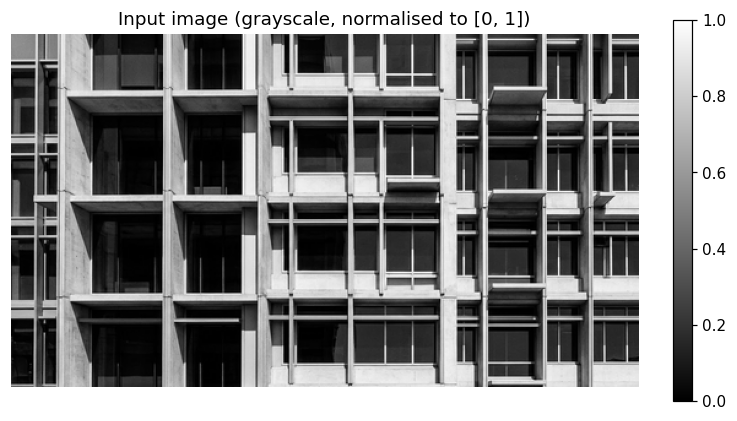

In [3]:
IMAGE_PATH = "building.jpg"
TARGET_W, TARGET_H = 512, 288   # both EVEN so 2x2 pooling divides exactly (288 -> 144, 512 -> 256)

def make_synthetic_facade(h=TARGET_H, w=TARGET_W):
    # Fallback image: dark windows in a bright concrete grid (strong horizontal + vertical edges, a gradient, a texture)
    img = np.full((h, w), 0.85, dtype=np.float32)
    for r in range(20, h - 20, 64):
        for c in range(24, w - 24, 80):
            img[r:r + 40, c:c + 56] = 0.12
            img[r + 18:r + 22, c:c + 56] = 0.55          # window mullion (horizontal)
            img[r:r + 40, c + 26:c + 30] = 0.55          # window mullion (vertical)
    img *= np.linspace(1.0, 0.7, w)[None, :]             # lighting gradient
    img += 0.02 * np.random.randn(h, w).astype(np.float32)  # concrete texture
    return np.clip(img, 0, 1)

if os.path.exists(IMAGE_PATH):
    pil = Image.open(IMAGE_PATH).convert("L")            # grayscale
    pil = pil.resize((TARGET_W, TARGET_H), Image.LANCZOS)
    img = np.asarray(pil, dtype=np.float32) / 255.0      # scale to [0, 1]
    print(f"Loaded '{IMAGE_PATH}'")
else:
    img = make_synthetic_facade()
    print(f"'{IMAGE_PATH}' not found -> using synthetic facade image")

print("Input shape (H, W):", img.shape, "| dtype:", img.dtype, "| range: [%.2f, %.2f]" % (img.min(), img.max()))
plt.figure(figsize=(8, 4.5))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title("Input image (grayscale, normalised to [0, 1])"); plt.axis("off"); plt.colorbar(fraction=0.03)
plt.show()

## Part I — Filter Pipeline Implementation & Visualization

### 1.1 Five custom 3×3 kernels

| # | Kernel | Matrix | What it responds to |
|---|---|---|---|
| 1 | Horizontal-Edge Detector (**Sobel-X / Gx**, as named in the assignment) | `[[-1,0,1],[-2,0,2],[-1,0,1]]` | Intensity **change along the x (horizontal) direction** → shows up on **vertical** lines/edges |
| 2 | Vertical-Edge Detector (**Sobel-Y / Gy**) | `[[-1,-2,-1],[0,0,0],[1,2,1]]` | Intensity **change along the y direction** → shows up on **horizontal** lines/edges |
| 3 | Sharpen | `[[0,-1,0],[-1,5,-1],[0,-1,0]]` | Boosts centre pixel vs neighbours (high-frequency boost) |
| 4 | Gaussian Blur | `1/16·[[1,2,1],[2,4,2],[1,2,1]]` | Low-pass smoothing |
| 5 | Emboss | `[[-2,-1,0],[-1,1,1],[0,1,2]]` | Directional (diagonal) gradient + original pixel → 3-D relief look |

> ⚠️ **Naming note (important for the viva):** the assignment labels Sobel-X as "horizontal edge detector". Sobel-X computes the gradient **in the horizontal direction (∂I/∂x)**, so it fires on **vertical** structures (e.g. window frames/columns). Sobel-Y computes ∂I/∂y and fires on **horizontal** structures (e.g. floor slabs/ledges). Be ready to explain this clearly.

In [4]:
kernels = {
    "1. Sobel-X (Horizontal-Edge Detector)": np.array([[-1, 0, 1],
                                                       [-2, 0, 2],
                                                       [-1, 0, 1]], dtype=np.float32),
    "2. Sobel-Y (Vertical-Edge Detector)":   np.array([[-1, -2, -1],
                                                       [ 0,  0,  0],
                                                       [ 1,  2,  1]], dtype=np.float32),
    "3. Sharpen":                            np.array([[ 0, -1,  0],
                                                       [-1,  5, -1],
                                                       [ 0, -1,  0]], dtype=np.float32),
    "4. Gaussian Blur (3x3)":                np.array([[1, 2, 1],
                                                       [2, 4, 2],
                                                       [1, 2, 1]], dtype=np.float32) / 16.0,
    "5. Emboss":                             np.array([[-2, -1, 0],
                                                       [-1,  1, 1],
                                                       [ 0,  1, 2]], dtype=np.float32),
}
for name, k in kernels.items():
    print(name, "| sum of weights = %.2f" % k.sum()); print(k, "\n")

1. Sobel-X (Horizontal-Edge Detector) | sum of weights = 0.00
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]] 

2. Sobel-Y (Vertical-Edge Detector) | sum of weights = 0.00
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]] 

3. Sharpen | sum of weights = 1.00
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]] 

4. Gaussian Blur (3x3) | sum of weights = 1.00
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]] 

5. Emboss | sum of weights = 1.00
[[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]] 



### 1.2 Building blocks (implemented from scratch with NumPy)

* **Convolution** — `'same'` zero padding (pad = 1) so the output keeps the input size: `H_out = H`, `W_out = W`.
* **ReLU** — `max(0, x)`.
* **Pooling (2×2, stride 2)** — non-overlapping blocks, output size = `H/2 × W/2`.

In [5]:
def conv2d_same(x, k):
    # 2-D cross-correlation, stride 1, zero padding so that output size == input size.
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2
    xp = np.pad(x, ((ph, ph), (pw, pw)), mode="constant", constant_values=0.0)
    windows = sliding_window_view(xp, (kh, kw))         # shape (H, W, kh, kw)
    return (windows * k).sum(axis=(-2, -1))             # element-wise multiply then sum = dot product per window

def relu(x):
    return np.maximum(0.0, x)

def pool2x2(x, mode="max"):
    # Non-overlapping 2x2 pooling with stride 2.
    H, W = x.shape
    H2, W2 = H // 2, W // 2
    blocks = x[:H2 * 2, :W2 * 2].reshape(H2, 2, W2, 2)  # group pixels into 2x2 blocks
    return blocks.max(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))

# ---------- Sanity checks (correctness proofs for your report) ----------
try:
    from scipy.signal import correlate2d
    ok = all(np.allclose(conv2d_same(img, k), correlate2d(img, k, mode="same", boundary="fill", fillvalue=0), atol=1e-5)
             for k in kernels.values())
    print("Custom conv == scipy.signal.correlate2d for all 5 kernels:", ok)
except ImportError:
    print("scipy not available - skipped cross-check")

t = np.array([[1, 2, 5, 6], [3, 4, 7, 8], [-1, -2, 0, 4], [-3, -4, 2, 2]], dtype=np.float32)
print("\nPooling unit test on a 4x4 matrix:\n", t)
print("MaxPool 2x2:\n", pool2x2(t, "max"))
print("AvgPool 2x2:\n", pool2x2(t, "avg"))

Custom conv == scipy.signal.correlate2d for all 5 kernels: True

Pooling unit test on a 4x4 matrix:
 [[ 1.  2.  5.  6.]
 [ 3.  4.  7.  8.]
 [-1. -2.  0.  4.]
 [-3. -4.  2.  2.]]
MaxPool 2x2:
 [[ 4.  8.]
 [-1.  4.]]
AvgPool 2x2:
 [[ 2.5  6.5]
 [-2.5  2. ]]


### 1.3 Run the pipeline — Stages A → B → C → D for each filter
* **Stage A** raw convolution (can be negative)
* **Stage B** ReLU(A)
* **Stage C** MaxPool(B)
* **Stage D** AvgPool(B)  ← both pools take the **post-ReLU** map as required

In [6]:
results = {}
for name, k in kernels.items():
    A = conv2d_same(img, k)          # Stage A
    B = relu(A)                      # Stage B
    C = pool2x2(B, "max")            # Stage C
    D = pool2x2(B, "avg")            # Stage D
    results[name] = {"A": A, "B": B, "C": C, "D": D}

print(f"{'Filter':<40}{'A (conv)':>14}{'B (ReLU)':>14}{'C (max-pool)':>14}{'D (avg-pool)':>14}")
for name, r in results.items():
    print(f"{name:<40}{str(r['A'].shape):>14}{str(r['B'].shape):>14}{str(r['C'].shape):>14}{str(r['D'].shape):>14}")

Filter                                        A (conv)      B (ReLU)  C (max-pool)  D (avg-pool)
1. Sobel-X (Horizontal-Edge Detector)       (288, 512)    (288, 512)    (144, 256)    (144, 256)
2. Sobel-Y (Vertical-Edge Detector)         (288, 512)    (288, 512)    (144, 256)    (144, 256)
3. Sharpen                                  (288, 512)    (288, 512)    (144, 256)    (144, 256)
4. Gaussian Blur (3x3)                      (288, 512)    (288, 512)    (144, 256)    (144, 256)
5. Emboss                                   (288, 512)    (288, 512)    (144, 256)    (144, 256)


### 1.4 The 5 × 4 comparative visualization grid
Rows = 5 filters, columns = Stages A, B, C, D, each with its own **colorbar**.

**Consistent intensity scaling (rubric item):** inside each row, one magnitude `m` (the 99.5th percentile of |Stage A|) is shared by all four panels:
* Stage A is drawn on `[-m, +m]` → **mid-gray = 0, darker = negative, brighter = positive**
* Stages B, C, D are drawn on `[0, m]` → **black = 0**, so the ReLU "blackout" is directly comparable to Stage A.

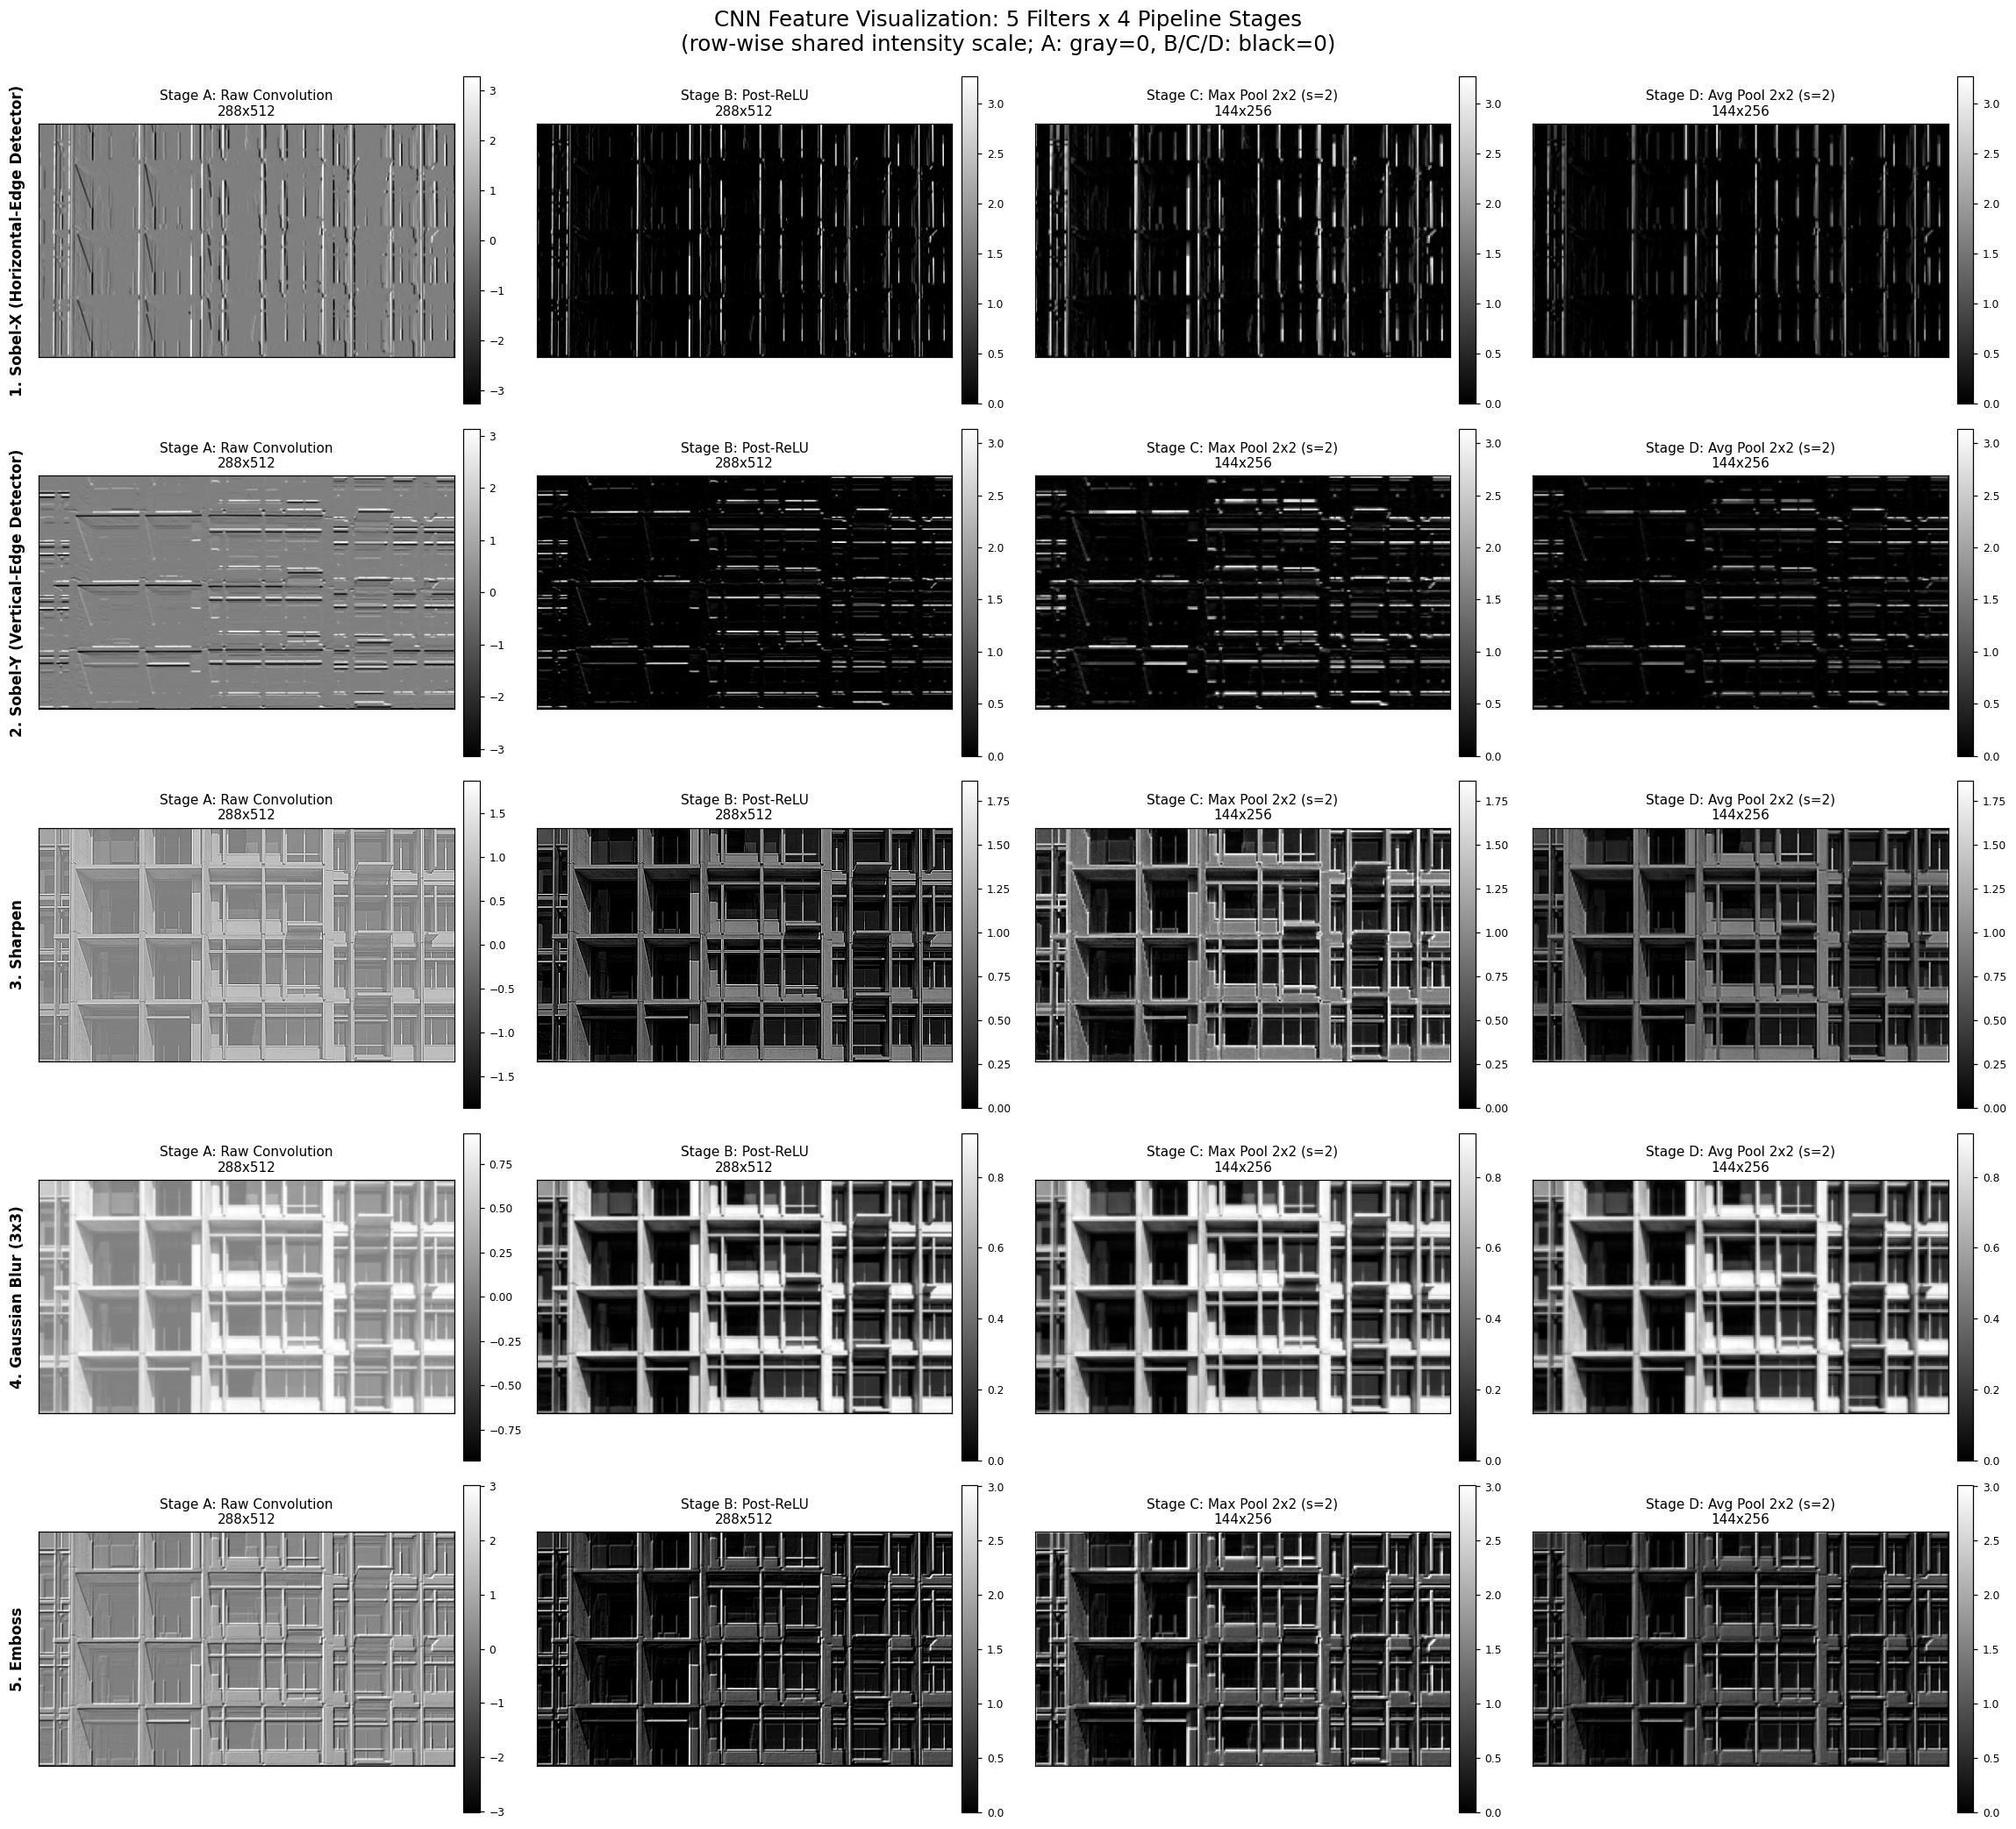

Saved: cnn_5x4_grid.png


In [7]:
stage_titles = ["Stage A: Raw Convolution", "Stage B: Post-ReLU", "Stage C: Max Pool 2x2 (s=2)", "Stage D: Avg Pool 2x2 (s=2)"]

fig, axes = plt.subplots(5, 4, figsize=(21, 19))
for i, (name, r) in enumerate(results.items()):
    m = np.percentile(np.abs(r["A"]), 99.5)          # shared scale for the whole row
    m = m if m > 0 else 1.0
    for j, key in enumerate(["A", "B", "C", "D"]):
        ax = axes[i, j]
        vmin = -m if key == "A" else 0.0
        im = ax.imshow(r[key], cmap="gray", vmin=vmin, vmax=m)
        ax.set_title(f"{stage_titles[j]}\n{r[key].shape[0]}x{r[key].shape[1]}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(name, fontsize=11, fontweight="bold", rotation=90, labelpad=10)
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        cb.ax.tick_params(labelsize=8)
fig.suptitle("CNN Feature Visualization: 5 Filters x 4 Pipeline Stages\n"
             "(row-wise shared intensity scale; A: gray=0, B/C/D: black=0)", fontsize=16, y=0.995)
plt.tight_layout()
fig.savefig("cnn_5x4_grid.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: cnn_5x4_grid.png")

### 1.5 Quantitative evidence table

In [8]:
print(f"{'Filter':<40}{'%neg in A':>11}{'%zero in B':>12}{'min(A)':>9}{'max(A)':>9}{'maxC':>8}{'maxD':>8}{'meanC':>8}{'meanD':>8}")
for name, r in results.items():
    A, B, C, D = r["A"], r["B"], r["C"], r["D"]
    print(f"{name:<40}{100*(A<0).mean():>10.1f}%{100*(B==0).mean():>11.1f}%"
          f"{A.min():>9.2f}{A.max():>9.2f}{C.max():>8.2f}{D.max():>8.2f}{C.mean():>8.3f}{D.mean():>8.3f}")
print("\nReading guide: maxC >= maxD always (max keeps the strongest peak, average dilutes it).")

Filter                                    %neg in A  %zero in B   min(A)   max(A)    maxC    maxD   meanC   meanD
1. Sobel-X (Horizontal-Edge Detector)         49.0%       53.0%    -3.83     4.00    4.00    3.24   0.290   0.177
2. Sobel-Y (Vertical-Edge Detector)           41.8%       45.4%    -3.73     3.78    3.78    3.01   0.245   0.150
3. Sharpen                                    18.0%       18.4%    -1.36     2.85    2.85    1.71   0.574   0.403
4. Gaussian Blur (3x3)                         0.0%        0.2%     0.00     0.95    0.95    0.95   0.400   0.364
5. Emboss                                     23.3%       23.9%    -2.70     4.36    4.36    3.34   0.683   0.494

Reading guide: maxC >= maxD always (max keeps the strongest peak, average dilutes it).


## Part II — Architectural Comparison & Parameter Audit

Input **32×32×3**. Both models: `Conv → ReLU → Pool → Conv → ReLU → Pool → Global Average Pooling → Dense(10)`.

| Model | Conv1 | Conv2 | Kernel | Pooling |
|---|---|---|---|---|
| A (Standard) | 5 filters | 10 filters | 3×3 | Max 2×2, s=2 |
| B (Large kernel) | 5 filters | 10 filters | 5×5 | Avg 2×2, s=2 |

Formula per conv layer: **(K_h × K_w × C_in + 1) × C_out** (the `+1` is the bias per filter).  
Dense layer: **(inputs + 1) × units**. Pooling, ReLU and GAP have **0** trainable parameters.

### 2.1 Manual (formula) calculation — done in code **before** `model.summary()`

In [9]:
def conv_params(kh, kw, cin, cout):
    return (kh * kw * cin + 1) * cout

def dense_params(n_in, n_out):
    return (n_in + 1) * n_out

def manual_audit(model_name, k, c_in=3, f1=5, f2=10, n_classes=10):
    print("=" * 70); print(model_name, f"(kernel {k}x{k})"); print("=" * 70)
    p1 = conv_params(k, k, c_in, f1)
    print(f"Conv1 : ({k}x{k}x{c_in} + 1) x {f1} = ({k*k*c_in} + 1) x {f1} = {k*k*c_in + 1} x {f1} = {p1}")
    p2 = conv_params(k, k, f1, f2)
    print(f"Conv2 : ({k}x{k}x{f1} + 1) x {f2} = ({k*k*f1} + 1) x {f2} = {k*k*f1 + 1} x {f2} = {p2}")
    print("Pooling (x2) and GAP : 0 parameters")
    pd = dense_params(f2, n_classes)
    print(f"Dense : ({f2} + 1) x {n_classes} = {pd}")
    total = p1 + p2 + pd
    print(f"TOTAL = {p1} + {p2} + {pd} = {total}   (conv-only = {p1 + p2})\n")
    return {"conv1": p1, "conv2": p2, "dense": pd, "conv_only": p1 + p2, "total": total}

manual_A = manual_audit("Model A (Standard)", 3)
manual_B = manual_audit("Model B (Large Kernel)", 5)

Model A (Standard) (kernel 3x3)
Conv1 : (3x3x3 + 1) x 5 = (27 + 1) x 5 = 28 x 5 = 140
Conv2 : (3x3x5 + 1) x 10 = (45 + 1) x 10 = 46 x 10 = 460
Pooling (x2) and GAP : 0 parameters
Dense : (10 + 1) x 10 = 110
TOTAL = 140 + 460 + 110 = 710   (conv-only = 600)

Model B (Large Kernel) (kernel 5x5)
Conv1 : (5x5x3 + 1) x 5 = (75 + 1) x 5 = 76 x 5 = 380
Conv2 : (5x5x5 + 1) x 10 = (125 + 1) x 10 = 126 x 10 = 1260
Pooling (x2) and GAP : 0 parameters
Dense : (10 + 1) x 10 = 110
TOTAL = 380 + 1260 + 110 = 1750   (conv-only = 1640)



### 2.2 Build both models in Keras and print `model.summary()`

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

def build_model(kernel_size, pool_type, name):
    Pool = layers.MaxPooling2D if pool_type == "max" else layers.AveragePooling2D
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(5,  kernel_size, padding="same", activation="relu", name="conv1"),
        Pool(pool_size=(2, 2), strides=2, name=f"{pool_type}_pool1"),
        layers.Conv2D(10, kernel_size, padding="same", activation="relu", name="conv2"),
        Pool(pool_size=(2, 2), strides=2, name=f"{pool_type}_pool2"),
        layers.GlobalAveragePooling2D(name="gap"),
        layers.Dense(10, activation="softmax", name="dense_out"),
    ], name=name)

model_A = build_model(3, "max", "Model_A_3x3_MaxPool")
model_B = build_model(5, "avg", "Model_B_5x5_AvgPool")

TensorFlow: 2.21.0


In [11]:
model_A.summary()

Model: "Model_A_3x3_MaxPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool1 (MaxPooling2D)        │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool2 (MaxPooling2D)        │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model_B.summary()

Model: "Model_B_5x5_AvgPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool1 (AveragePooling2D)    │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool2 (AveragePooling2D)    │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

### 2.3 Audit table: manual count vs. framework output (with automatic verification)

In [13]:
code_A, code_B = model_A.count_params(), model_B.count_params()
trainable_A = int(sum(np.prod(w.shape) for w in model_A.trainable_weights))
trainable_B = int(sum(np.prod(w.shape) for w in model_B.trainable_weights))

assert manual_A["total"] == code_A == trainable_A, "Model A mismatch!"
assert manual_B["total"] == code_B == trainable_B, "Model B mismatch!"
print("VERIFIED: manual count == model.summary() count for BOTH models\n")

hdr = f"{'Model Configuration':<22}{'Conv Architecture':<30}{'Kernel':<8}{'Pooling':<22}{'Manual Count':>13}{'Code Output':>13}"
print(hdr); print("-" * len(hdr))
print(f"{'Model A (Standard)':<22}{'Conv1: 5 f, Conv2: 10 f':<30}{'3 x 3':<8}{'Max (2x2, s=2)':<22}{manual_A['total']:>13}{code_A:>13}")
print(f"{'Model B (Large Kernel)':<22}{'Conv1: 5 f, Conv2: 10 f':<30}{'5 x 5':<8}{'Avg (2x2, s=2)':<22}{manual_B['total']:>13}{code_B:>13}")

inc_total = 100 * (manual_B["total"] - manual_A["total"]) / manual_A["total"]
inc_conv  = 100 * (manual_B["conv_only"] - manual_A["conv_only"]) / manual_A["conv_only"]
print(f"\nIncrease A -> B (TOTAL params, incl. Dense): ({manual_B['total']} - {manual_A['total']}) / {manual_A['total']} = {inc_total:.2f}%")
print(f"Increase A -> B (conv layers only)         : ({manual_B['conv_only']} - {manual_A['conv_only']}) / {manual_A['conv_only']} = {inc_conv:.2f}%")

VERIFIED: manual count == model.summary() count for BOTH models

Model Configuration   Conv Architecture             Kernel  Pooling                Manual Count  Code Output
------------------------------------------------------------------------------------------------------------
Model A (Standard)    Conv1: 5 f, Conv2: 10 f       3 x 3   Max (2x2, s=2)                  710          710
Model B (Large Kernel)Conv1: 5 f, Conv2: 10 f       5 x 5   Avg (2x2, s=2)                 1750         1750

Increase A -> B (TOTAL params, incl. Dense): (1750 - 710) / 710 = 146.48%
Increase A -> B (conv layers only)         : (1640 - 600) / 600 = 173.33%


### 2.4 Receptive-field equivalence & parameter savings (supports Question 3)

Receptive field of stacked stride-1 convs: `RF = 1 + Σ (k_i − 1)`.  
Two stacked 3×3 layers → `1 + 2 + 2 = 5` → same 5×5 receptive field.

In [14]:
def receptive_field(kernels_list):
    rf = 1
    for k in kernels_list: rf += (k - 1)          # all strides = 1 inside the stack
    return rf

for n in (1, 2, 3):
    print(f"{n} stacked 3x3 layer(s) -> receptive field {receptive_field([3]*n)}x{receptive_field([3]*n)}")
print("Layers of 3x3 needed to match one 5x5 :", next(n for n in range(1, 10) if receptive_field([3]*n) == 5))

print("\n--- (a) General case, C channels in and out (the textbook result) ---")
for C in (1, 5, 10, 64):
    one5  = 25 * C * C
    two3  = 2 * 9 * C * C
    print(f"C={C:>3}: one 5x5 = 25C^2 = {one5:>6} | two 3x3 = 18C^2 = {two3:>6} | saved = {one5 - two3:>5} ({100*(one5-two3)/one5:.0f}%)")

print("\n--- (b) Including biases, per layer of YOUR models, two 3x3 with intermediate channels = C_out ---")
for lname, cin, cout in (("Conv1", 3, 5), ("Conv2", 5, 10)):
    five = conv_params(5, 5, cin, cout)
    stacked = conv_params(3, 3, cin, cout) + conv_params(3, 3, cout, cout)
    print(f"{lname}: 5x5 = {five:>5} | 3x3+3x3 = {conv_params(3,3,cin,cout)} + {conv_params(3,3,cout,cout)} = {stacked:>5} | difference (5x5 - stacked) = {five - stacked:+d}")
print("\nNote: with small, unequal channel counts (Conv2: 5 -> 10) the stacked version can cost MORE; "
      "the 28% saving (18C^2 vs 25C^2) holds when C_in = C_out = C. Mention both in the viva.")

1 stacked 3x3 layer(s) -> receptive field 3x3
2 stacked 3x3 layer(s) -> receptive field 5x5
3 stacked 3x3 layer(s) -> receptive field 7x7
Layers of 3x3 needed to match one 5x5 : 2

--- (a) General case, C channels in and out (the textbook result) ---
C=  1: one 5x5 = 25C^2 =     25 | two 3x3 = 18C^2 =     18 | saved =     7 (28%)
C=  5: one 5x5 = 25C^2 =    625 | two 3x3 = 18C^2 =    450 | saved =   175 (28%)
C= 10: one 5x5 = 25C^2 =   2500 | two 3x3 = 18C^2 =   1800 | saved =   700 (28%)
C= 64: one 5x5 = 25C^2 = 102400 | two 3x3 = 18C^2 =  73728 | saved = 28672 (28%)

--- (b) Including biases, per layer of YOUR models, two 3x3 with intermediate channels = C_out ---
Conv1: 5x5 =   380 | 3x3+3x3 = 140 + 230 =   370 | difference (5x5 - stacked) = +10
Conv2: 5x5 =  1260 | 3x3+3x3 = 460 + 910 =  1370 | difference (5x5 - stacked) = -110

Note: with small, unequal channel counts (Conv2: 5 -> 10) the stacked version can cost MORE; the 28% saving (18C^2 vs 25C^2) holds when C_in = C_out = C. M

## Part III — Evidence cells for the Critical-Analysis answers (Q1–Q5)
These cells only **generate evidence**; write your final answers in your own words from what you see in *your* grid.

### Q1 evidence — ReLU vs Leaky-ReLU (α = 0.1) vs Sigmoid on the two edge filters

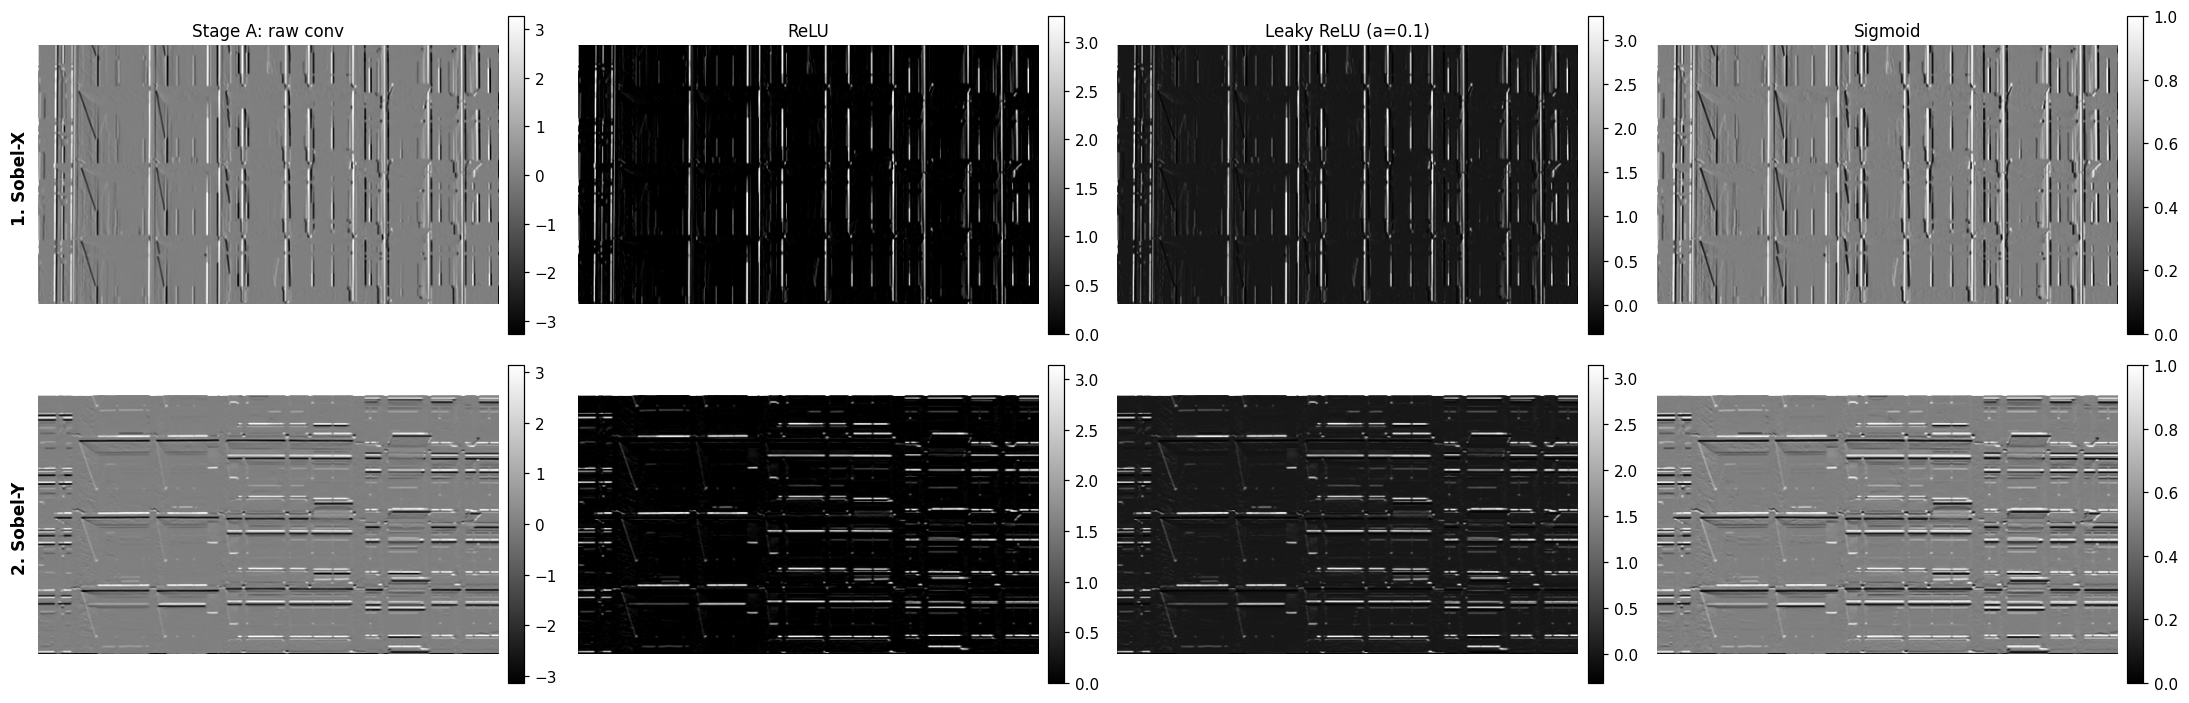

1. Sobel-X   negative pixels: 49.0% | ReLU zeroes 53.0% | Leaky keeps min = -0.383 (A.min = -3.831) | Sigmoid(0) = 0.5 -> flat regions become mid-gray, range (0,1)
2. Sobel-Y   negative pixels: 41.8% | ReLU zeroes 45.4% | Leaky keeps min = -0.373 (A.min = -3.729) | Sigmoid(0) = 0.5 -> flat regions become mid-gray, range (0,1)


In [15]:
def leaky_relu(x, a=0.1): return np.where(x > 0, x, a * x)
def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))

rows = list(results.items())[:2]                      # Sobel-X and Sobel-Y
cols = [("Stage A: raw conv", None), ("ReLU", relu), ("Leaky ReLU (a=0.1)", leaky_relu), ("Sigmoid", sigmoid)]
fig, axes = plt.subplots(2, 4, figsize=(20, 6.5))
for i, (name, r) in enumerate(rows):
    A = r["A"]; m = np.percentile(np.abs(A), 99.5)
    for j, (t, f) in enumerate(cols):
        out = A if f is None else f(A)
        if f is None:          vmin, vmax = -m, m
        elif f is sigmoid:     vmin, vmax = 0, 1
        elif f is leaky_relu:  vmin, vmax = -0.1 * m, m
        else:                  vmin, vmax = 0, m
        im = axes[i, j].imshow(out, cmap="gray", vmin=vmin, vmax=vmax)
        axes[i, j].set_title(t if i == 0 else "", fontsize=11); axes[i, j].axis("off")
        fig.colorbar(im, ax=axes[i, j], fraction=0.046, pad=0.02)
    axes[i, 0].text(-0.02, 0.5, name.split("(")[0], transform=axes[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

for name, r in rows:
    A = r["A"]
    print(f"{name.split('(')[0]:<12} negative pixels: {100*(A<0).mean():.1f}% | ReLU zeroes {100*(relu(A)==0).mean():.1f}% | "
          f"Leaky keeps min = {leaky_relu(A).min():.3f} (A.min = {A.min():.3f}) | Sigmoid(0) = 0.5 -> flat regions become mid-gray, range (0,1)")

### Q2 evidence — Max vs Average pooling (peak retention, and dark text on white background)

Peak retention after pooling (Sharpen & Edge rows): fraction of the Stage-B maximum that survives
1. Sobel-X (Horizontal-Edge Detector)    max-pool keeps 100.0% of peak | avg-pool keeps  81.1% of peak
2. Sobel-Y (Vertical-Edge Detector)      max-pool keeps 100.0% of peak | avg-pool keeps  79.6% of peak
3. Sharpen                               max-pool keeps 100.0% of peak | avg-pool keeps  60.0% of peak


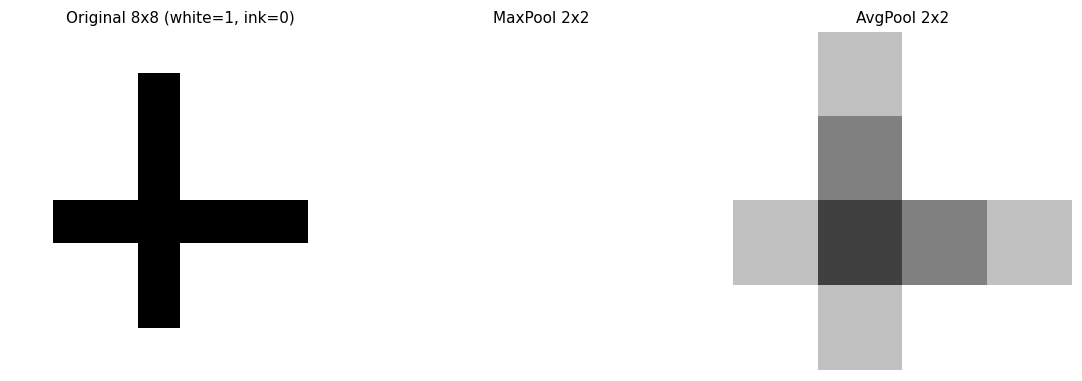

Ink pixels remaining darker than background  -> MaxPool: 0 | AvgPool: 7
MaxPool output:
 [[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]
AvgPool output:
 [[1.   0.75 1.   1.  ]
 [1.   0.5  1.   1.  ]
 [0.75 0.25 0.5  0.75]
 [1.   0.75 1.   1.  ]]


In [16]:
print("Peak retention after pooling (Sharpen & Edge rows): fraction of the Stage-B maximum that survives")
for name, r in results.items():
    if name.startswith(("1", "2", "3")):
        print(f"{name:<40} max-pool keeps {100*r['C'].max()/r['B'].max():5.1f}% of peak | avg-pool keeps {100*r['D'].max()/r['B'].max():5.1f}% of peak")

# Dark ink on a pure-white page (values near 255 -> 1.0). Thin 1-pixel-wide strokes.
page = np.ones((8, 8), dtype=np.float32)               # white background = 1.0
page[1:7, 3] = 0.0                                     # vertical dark stroke (1 px wide)
page[4, 1:7] = 0.0                                     # horizontal dark stroke (1 px wide)
mx, av = pool2x2(page, "max"), pool2x2(page, "avg")
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a, d, t in zip(ax, (page, mx, av), ("Original 8x8 (white=1, ink=0)", "MaxPool 2x2", "AvgPool 2x2")):
    a.imshow(d, cmap="gray", vmin=0, vmax=1); a.set_title(t, fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()
print("Ink pixels remaining darker than background  -> MaxPool:", int((mx < 1).sum()), "| AvgPool:", int((av < 1).sum()))
print("MaxPool output:\n", mx); print("AvgPool output:\n", np.round(av, 2))

### Q3 evidence — exact percentage increase

In [17]:
print(f"Model A total = {manual_A['total']},  Model B total = {manual_B['total']}")
print(f"Total increase  = {inc_total:.2f}%   (= {manual_B['total']-manual_A['total']} extra parameters)")
print(f"Conv-only increase = {inc_conv:.2f}%  (Dense head = {manual_A['dense']} params in both models, unchanged)")

Model A total = 710,  Model B total = 1750
Total increase  = 146.48%   (= 1040 extra parameters)
Conv-only increase = 173.33%  (Dense head = 110 params in both models, unchanged)


### Q4 evidence — is `Conv→ReLU→MaxPool` identical to `Conv→MaxPool→ReLU`?

In [18]:
# (1) On the 2x2 sample patch with negative numbers
patch = np.array([[-4.0, 2.0], [-1.0, -3.0]])
print("Patch:\n", patch)
print("Conv->ReLU->MaxPool :", relu(patch).max(),  "  (relu -> [[0,2],[0,0]] -> max = 2)")
print("Conv->MaxPool->ReLU :", max(patch.max(), 0.0), "  (max = 2 -> relu(2) = 2)")
all_neg = np.array([[-4.0, -2.0], [-1.0, -3.0]])
print("All-negative patch  :", relu(all_neg).max(), "vs", max(all_neg.max(), 0.0), " (both 0: still identical)")

# (2) On every real feature map from Part I
same = all(np.array_equal(pool2x2(relu(r["A"]), "max"), relu(pool2x2(r["A"], "max"))) for r in results.values())
print("\nIdentical for all 5 real feature maps (MaxPool):", same)

# (3) Contrast: Average pooling is NOT commutative with ReLU
print("Avg: ReLU->AvgPool =", relu(patch).mean(), "| AvgPool->ReLU =", relu(patch.mean()), "  -> DIFFERENT")

# (4) Efficiency: number of ReLU evaluations
H, W = results[list(results)[0]]["A"].shape
print(f"\nReLU evaluations per feature map -> Conv->ReLU->Pool: {H*W:,} | Conv->Pool->ReLU: {H*W//4:,}  (4x fewer)")

Patch:
 [[-4.  2.]
 [-1. -3.]]
Conv->ReLU->MaxPool : 2.0   (relu -> [[0,2],[0,0]] -> max = 2)
Conv->MaxPool->ReLU : 2.0   (max = 2 -> relu(2) = 2)
All-negative patch  : 0.0 vs 0.0  (both 0: still identical)

Identical for all 5 real feature maps (MaxPool): True
Avg: ReLU->AvgPool = 0.5 | AvgPool->ReLU = 0.0   -> DIFFERENT

ReLU evaluations per feature map -> Conv->ReLU->Pool: 147,456 | Conv->Pool->ReLU: 36,864  (4x fewer)


### Q5 note
Q5 is conceptual (filter collapse: e.g. identical/poor weight initialization, too-high learning rate → dead ReLUs, etc.). No code needed, but you can optionally demonstrate it later with a short training experiment — we will cover it in the viva-prep step.

---
**Files produced by this notebook:** `cnn_5x4_grid.png` (grid figure for your report). For Part II, also take a screenshot of the two `model.summary()` outputs and attach your hand-written calculations.